In [16]:
from google.colab import files
uploaded = files.upload()

Saving retail_sales_dataset.csv to retail_sales_dataset.csv


In [17]:
import pandas as pd
df = pd.read_csv("retail_sales_dataset.csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(1000, 9)
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [18]:
# Basic inspection: structure, types, missing values, duplicates
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df["Date"] = pd.to_datetime(df["Date"])
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nNull values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Shape: (1000, 9)

Data types:
 Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object

Null values:
 Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate rows: 0


In [19]:
# Mean, median, mode and standard deviation of numeric columns
num_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]
stats = pd.DataFrame({
    "mean": df[num_cols].mean(),
    "median": df[num_cols].median(),
    "mode": df[num_cols].mode().iloc[0],
    "std": df[num_cols].std(),
})
stats

,mean,median,mode,std
Age,41.392,42.0,43.0,13.681430
Quantity,2.514,3.0,4.0,1.132734
Price per Unit,179.890,50.0,50.0,189.681356
Total Amount,456.000,135.0,50.0,559.997632


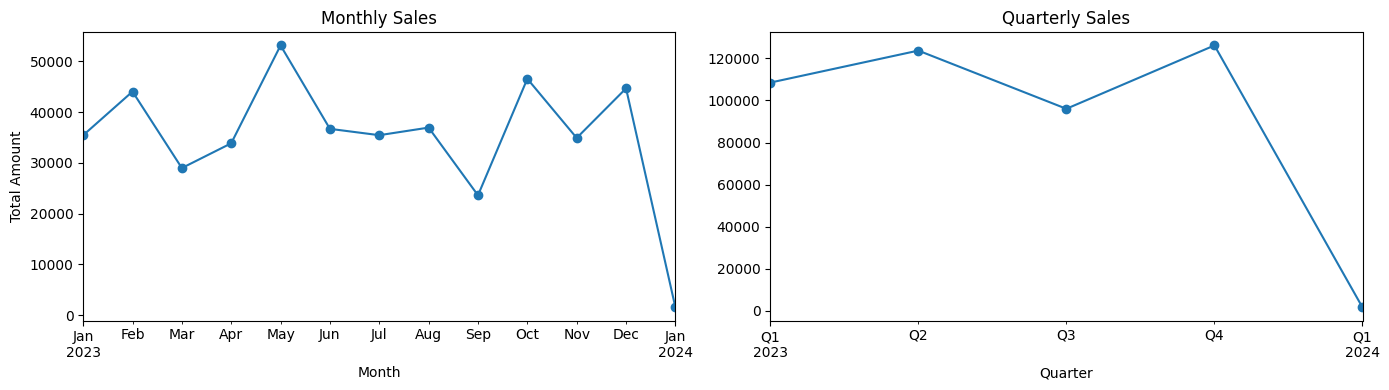

In [20]:
# Time series analysis
df["Month"] = df["Date"].dt.to_period("M")
df["Quarter"] = df["Date"].dt.to_period("Q")

monthly = df.groupby("Month")["Total Amount"].sum()
quarterly = df.groupby("Quarter")["Total Amount"].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
monthly.plot(ax=axes[0], marker="o", title="Monthly Sales")
quarterly.plot(ax=axes[1], marker="o", title="Quarterly Sales")
axes[0].set_ylabel("Total Amount")
plt.tight_layout()
plt.show()

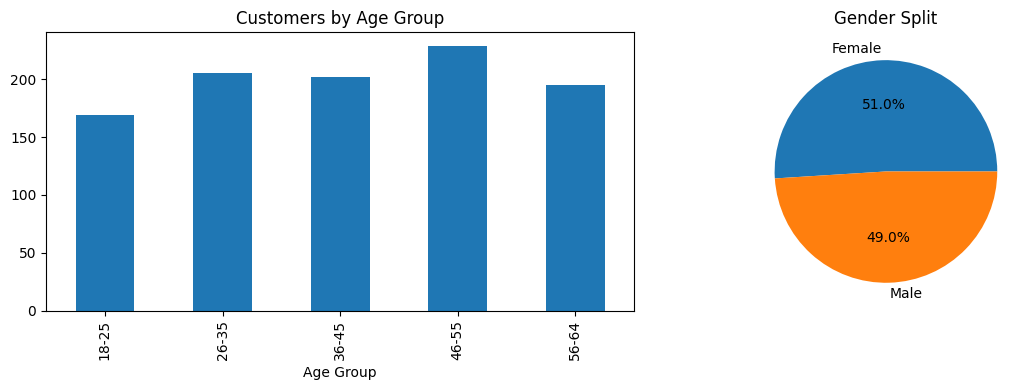

In [21]:
# Customer demographics
df["Age Group"] = pd.cut(df["Age"], bins=[17, 25, 35, 45, 55, 65],
                         labels=["18-25", "26-35", "36-45", "46-55", "56-64"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["Age Group"].value_counts().sort_index().plot(kind="bar", ax=axes[0], title="Customers by Age Group")
df["Gender"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=axes[1], title="Gender Split")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

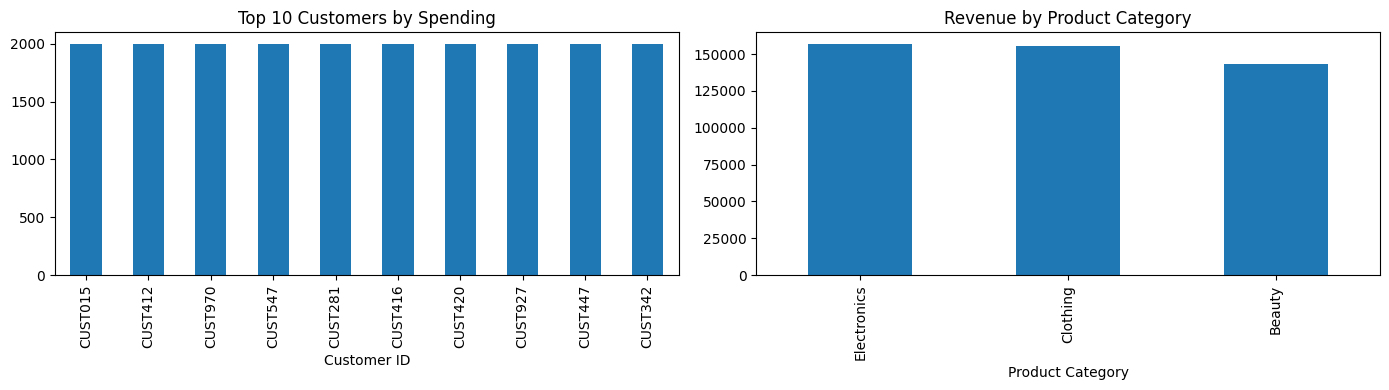

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


In [22]:
# The dataset has no product names, so top 10 customers and category revenue are used
top_customers = df.groupby("Customer ID")["Total Amount"].sum().sort_values(ascending=False).head(10)
category_revenue = df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
top_customers.plot(kind="bar", ax=axes[0], title="Top 10 Customers by Spending")
category_revenue.plot(kind="bar", ax=axes[1], title="Revenue by Product Category")
plt.tight_layout()
plt.show()
print(category_revenue)

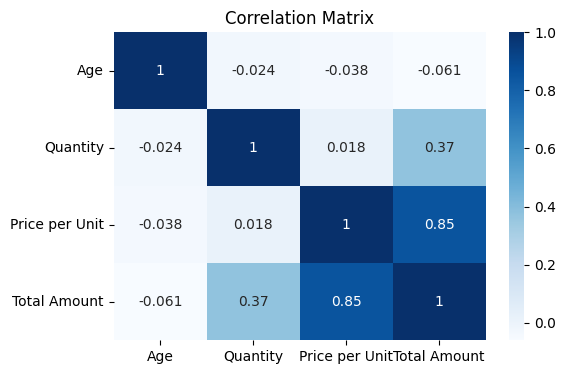

In [23]:
# Correlation between numeric variables
plt.figure(figsize=(6, 4))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="Blues")
plt.title("Correlation Matrix")
plt.show()

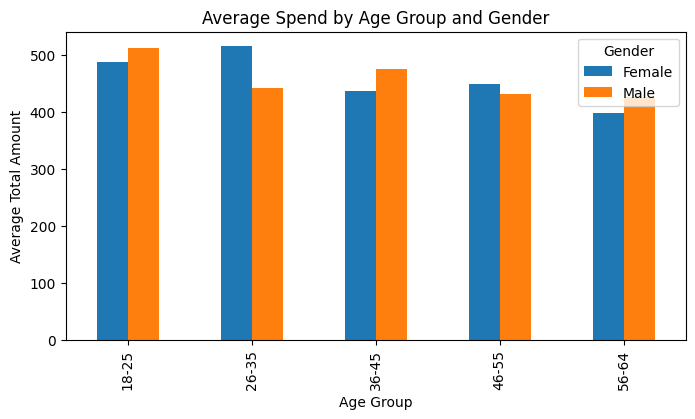

Gender,Female,Male
Age Group,,
18-25,487.283951,512.272727
26-35,515.093458,442.500000
36-45,436.775701,475.105263
46-55,447.983193,430.727273
56-64,398.020833,426.262626


In [24]:
# Average spending by age group and gender
pivot = df.pivot_table(values="Total Amount", index="Age Group", columns="Gender", aggfunc="mean", observed=True)
pivot.plot(kind="bar", figsize=(8, 4), title="Average Spend by Age Group and Gender")
plt.ylabel("Average Total Amount")
plt.show()
pivot

In [ ]:
import os, json, shutil
os.chdir("/content")
from getpass import getpass
from google.colab import _message

token = getpass("Paste GitHub token: ").strip()
if not (token.startswith("ghp_") or token.startswith("github_pat_")) or len(token) > 120:
    raise SystemExit("This is not a GitHub token. Copy the token (starts with ghp_) and run the cell again.")

nb = _message.blocking_request('get_ipynb', timeout_sec=120)['ipynb']

!rm -rf /content/OIBSIP
!git clone https://{token}@github.com/Ali-Bin-Talib/OIBSIP.git /content/OIBSIP

folder = "/content/OIBSIP/DataAnalytics-L1-EDARetailSales"
os.makedirs(folder, exist_ok=True)

with open(folder + "/EDA_Retail_Sales.ipynb", "w") as f:
    json.dump(nb, f)

shutil.copy("/content/retail_sales_dataset.csv", folder + "/retail_sales_dataset.csv")

readme = """# EDA on Retail Sales Data

Exploratory data analysis of a retail sales dataset (1000 transactions) to find sales trends, customer behaviour and business insights.

## What this project does
- Data inspection: shape, data types, null values, duplicates
- Descriptive statistics: mean, median, mode, standard deviation
- Monthly and quarterly sales trends
- Customer demographics: age groups and gender
- Top 10 customers and revenue by product category
- Correlation heatmap
- Extra insight: average spend by age group and gender
- Conclusion with business recommendations

## Dataset
Retail Sales Dataset by Mohammad Talib (Kaggle). It has no product names, so top customers and category revenue are used instead of top products.

## Tech Stack
Python, pandas, numpy, matplotlib, seaborn, Jupyter Notebook (Google Colab)

## How to Run
Open EDA_Retail_Sales.ipynb in Google Colab, upload retail_sales_dataset.csv and run all cells.
"""
with open(folder + "/README.md", "w") as f:
    f.write(readme)

os.chdir("/content/OIBSIP")
!git config user.email "alibintalib853@gmail.com"
!git config user.name "Ali Bin Talib"
!git add .
!git commit -m "Data Analytics L1: EDA on Retail Sales Data"
!git push
os.chdir("/content")

Paste GitHub token: ··········
